# CubicGalileonEmu: demo

`CubicGalileonEmu` exposes a single function, `emulate(params, z)`, that returns the emulated
boost factor $B(k)$ and its uncertainty for the cubic Galileon gravity model.

This notebook shows how to call it and checks it against held-out Hi-COLA simulations.
Install the package with the example extras from the repository root: `pip install '.[examples]'`.

## Emulating the boost

In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt

from CubicGalileonEmu import emulate, PARAM_NAMES, PARAM_MIN, PARAM_MAX, Z_MIN, Z_MAX

print('Parameters:', PARAM_NAMES)
print('Training range min:', PARAM_MIN)
print('Training range max:', PARAM_MAX)
print('Redshift range: [%g, %g]' % (Z_MIN, Z_MAX))

Parameters: ['Omega_m', 'n_s', '1e9 A_s', 'h', 'f_phi']
Training range min: [0.27485995 0.85       1.453      0.61       0.02      ]
Training range max: [0.33115569 1.1        3.291      0.73       1.        ]
Redshift range: [0, 15.892]


(768,) (1, 768) (1, 768)


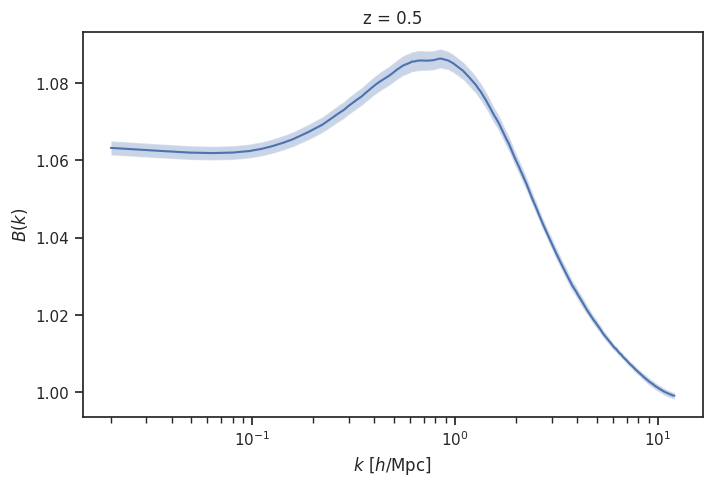

In [2]:
params = [0.31, 0.96, 2.1, 0.68, 0.5]   # [Omega_m, n_s, 1e9 A_s, h, f_phi]

k, Bk_mean, Bk_std = emulate(params, z=0.5)
print(k.shape, Bk_mean.shape, Bk_std.shape)

plt.figure(figsize=(8, 5))
plt.plot(k, Bk_mean[0])
plt.fill_between(k, Bk_mean[0] - Bk_std[0], Bk_mean[0] + Bk_std[0], alpha=0.3)
plt.xscale('log')
plt.xlabel(r'$k\ [h/{\rm Mpc}]$')
plt.ylabel(r'$B(k)$')
plt.title('z = 0.5');

Several cosmologies can be emulated at once by passing an `(n, 5)` array. Here $f_\phi$ is varied with the other parameters fixed, at several redshifts.

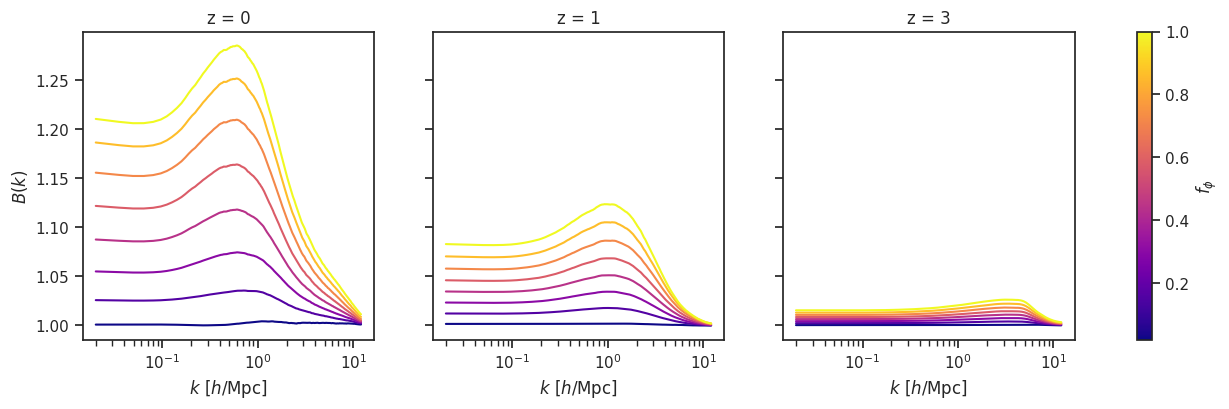

In [3]:
p_mid = 0.5 * (PARAM_MIN + PARAM_MAX)
f_phi = np.linspace(PARAM_MIN[4], PARAM_MAX[4], 8)
batch = np.tile(p_mid, (len(f_phi), 1))
batch[:, 4] = f_phi

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
cmap = plt.cm.plasma
for ax, z in zip(axes, [0.0, 1.0, 3.0]):
    k, Bk_mean, _ = emulate(batch, z)
    for i, f in enumerate(f_phi):
        ax.plot(k, Bk_mean[i], color=cmap(i / (len(f_phi) - 1)))
    ax.set_xscale('log')
    ax.set_xlabel(r'$k\ [h/{\rm Mpc}]$')
    ax.set_title('z = %g' % z)
axes[0].set_ylabel(r'$B(k)$')
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(f_phi.min(), f_phi.max()))
fig.colorbar(sm, ax=axes, label=r'$f_\phi$');

## Validation against held-out simulations

Two validation sets are provided in `examples/data/`: a generic one inside the training box and an *edge* set near its boundary. The validation redshift grid is twice as fine as the training grid, so every other validation redshift lies between two training snapshots and tests the redshift interpolation.

In [4]:
DATA = 'data'

def load_params(fname):
    p = np.loadtxt(os.path.join(DATA, fname))
    p[:, 2] /= 1e-9  # A_s rescaling
    return p

def load_zk(fname):
    zk = np.loadtxt(os.path.join(DATA, fname))
    return zk[:, 0][np.isfinite(zk[:, 0])], zk[:, 1]

def load_boost(fname, n_z, n_k):
    # Reads only the complete simulations (the edge file may be partially written)
    with open(os.path.join(DATA, fname), 'rb') as f:
        np.lib.format.read_magic(f)
        np.lib.format.read_array_header_1_0(f)
        raw = np.frombuffer(f.read(), dtype=np.float64)
    n_sims = raw.size // (n_z * n_k)
    return raw[:n_sims * n_z * n_k].reshape(n_sims, n_z, n_k)

z_val, k_val = load_zk('z_k_validation.txt')
Bk_val = load_boost('Boost_validation.npy', len(z_val), len(k_val))
p_val = load_params('cosmo_validation.txt')[:Bk_val.shape[0]]

z_edge, k_edge = load_zk('z_k_validation_edges.txt')
Bk_edge = load_boost('Boost_validation_edges.npy', len(z_edge), len(k_edge))
p_edge = load_params('cosmo_validation_edges.txt')[:Bk_edge.shape[0]]

print('Generic validation:', Bk_val.shape, ' Edge validation:', Bk_edge.shape)

# The edge set deliberately probes the boundary of (and slightly beyond) the training box,
# so silence the emulator's extrapolation warning for this notebook.
warnings.filterwarnings('ignore', message='Some parameters are outside the training range')

Generic validation: (25, 101, 768)  Edge validation: (24, 101, 768)


### Validation design
The grey box is the training range.

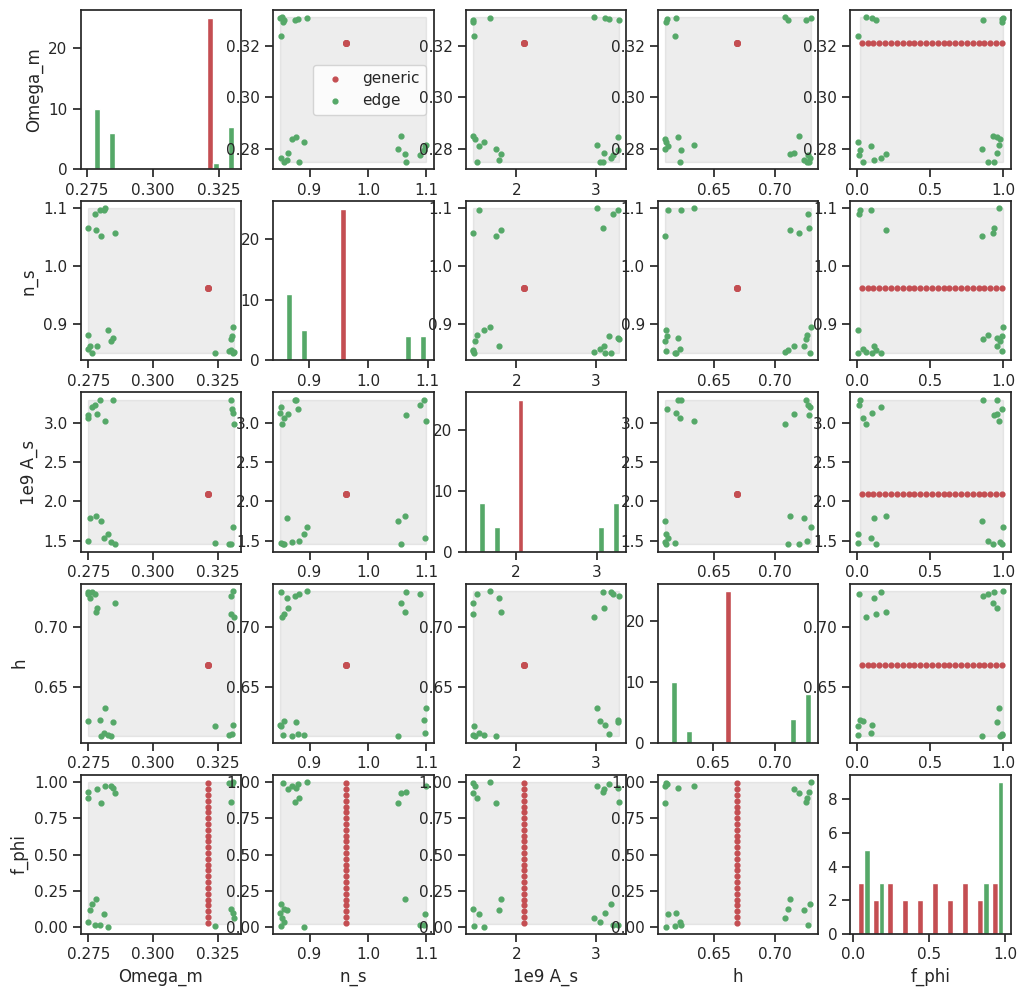

In [5]:
n = len(PARAM_NAMES)
fig, axes = plt.subplots(n, n, figsize=(12, 12))
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i == j:
            ax.hist([p_val[:, i], p_edge[:, i]], color=['r', 'g'], bins=10, range=(PARAM_MIN[i], PARAM_MAX[i]))
        else:
            ax.add_patch(plt.Rectangle((PARAM_MIN[j], PARAM_MIN[i]), PARAM_MAX[j] - PARAM_MIN[j],
                                       PARAM_MAX[i] - PARAM_MIN[i], color='k', alpha=0.08))
            ax.scatter(p_val[:, j], p_val[:, i], c='r', s=12, label='generic')
            ax.scatter(p_edge[:, j], p_edge[:, i], c='g', s=12, label='edge')
        if i == n - 1: ax.set_xlabel(PARAM_NAMES[j])
        if j == 0: ax.set_ylabel(PARAM_NAMES[i])
axes[0, 1].legend();

### Emulated vs simulated $B(k)$
At a training-snapshot redshift and at a redshift between snapshots. The shaded band in the lower panels marks 1% and 2% errors.

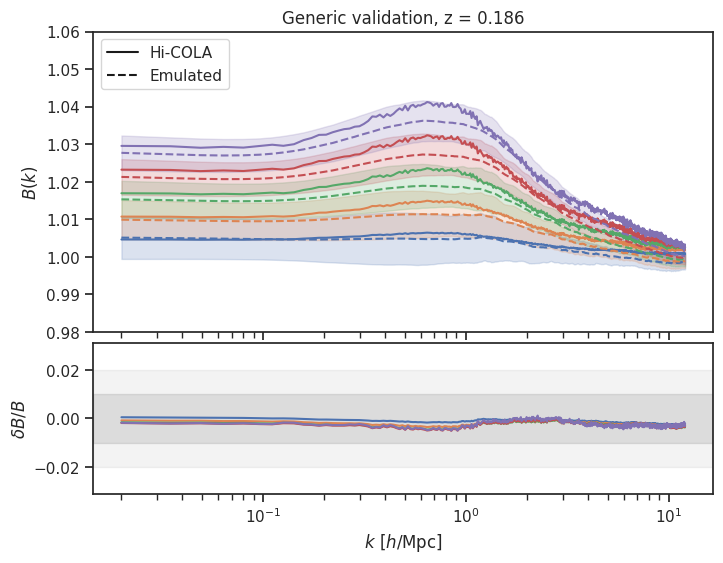

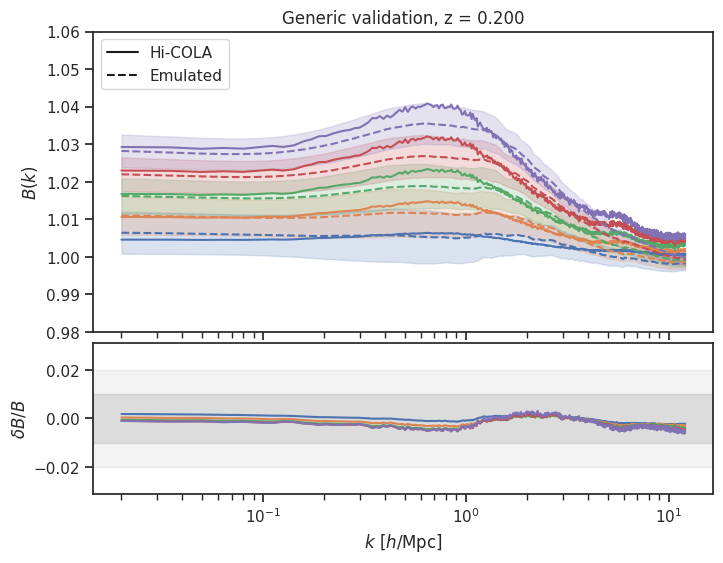

In [6]:
def validation_plot(k, truth, mean, std, title, ylim):
    fig, a = plt.subplots(2, 1, figsize=(8, 6), gridspec_kw={'height_ratios': [2, 1]}, sharex=True)
    plt.subplots_adjust(hspace=0.05)
    for i in range(mean.shape[0]):
        c = 'C%d' % i
        a[0].plot(k, truth[i], c=c, ls='-')
        a[0].plot(k, mean[i], c=c, ls='--')
        a[0].fill_between(k, mean[i] - std[i], mean[i] + std[i], color=c, alpha=0.2)
        a[1].plot(k, mean[i] / truth[i] - 1, c=c)
    a[0].plot(np.nan, np.nan, 'k-', label='Hi-COLA')
    a[0].plot(np.nan, np.nan, 'k--', label='Emulated')
    a[0].legend(loc='upper left')
    a[1].axhspan(-0.02, 0.02, color='k', alpha=0.05)
    a[1].axhspan(-0.01, 0.01, color='k', alpha=0.1)
    a[0].set_xscale('log')
    a[0].set_ylim(*ylim)
    a[1].set_ylim(-0.031, 0.031)
    a[0].set_ylabel(r'$B(k)$')
    a[1].set_ylabel(r'$\delta B/B$')
    a[1].set_xlabel(r'$k\ [h/{\rm Mpc}]$')
    a[0].set_title(title)
    return fig

n_show = 5
for zi in [16, 17]:   # z_val[16] is a training snapshot, z_val[17] lies between two
    k, mean, std = emulate(p_val[:n_show], z_val[zi])
    validation_plot(k, Bk_val[:n_show, zi], mean, std, 'Generic validation, z = %.3f' % z_val[zi], (0.98, 1.06))

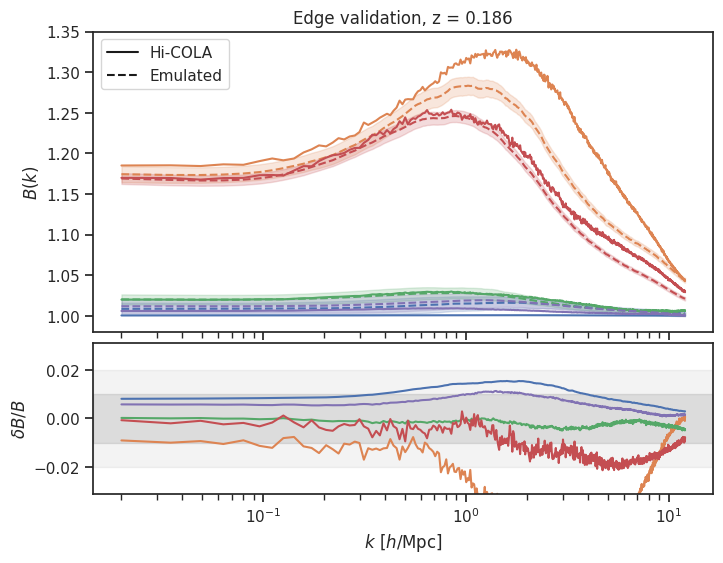

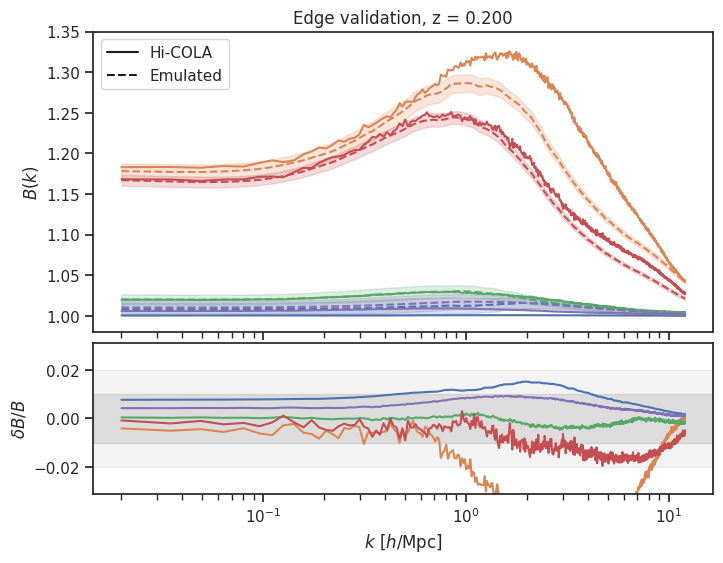

In [7]:
for zi in [16, 17]:
    k, mean, std = emulate(p_edge[:n_show], z_edge[zi])
    validation_plot(k, Bk_edge[:n_show, zi], mean, std, 'Edge validation, z = %.3f' % z_edge[zi], (0.98, 1.35))

### Error summary across redshift
For every validation cosmology and redshift, the largest fractional error over $k < 1.2\,h/$Mpc. Lines show the median and maximum over cosmologies.

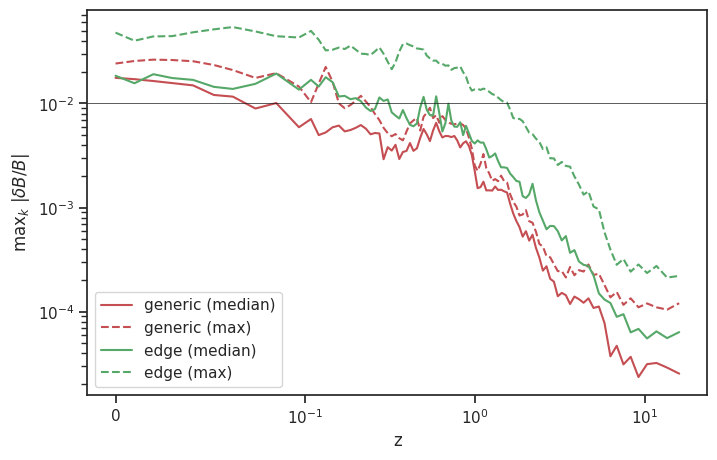

In [8]:
def error_vs_z(p, Bk, z_grid, k_max=1.2):
    zs, med, worst = [], [], []
    for zi, z in enumerate(z_grid):
        if not Z_MIN <= z <= Z_MAX:
            continue
        k, mean, _ = emulate(p, z)
        sel = k < k_max
        err = np.max(np.abs(mean[:, sel] / Bk[:, zi, sel] - 1), axis=1)
        zs.append(z); med.append(np.median(err)); worst.append(err.max())
    return np.array(zs), np.array(med), np.array(worst)

plt.figure(figsize=(8, 5))
for label, p, Bk, zg, c in [('generic', p_val, Bk_val, z_val, 'r'), ('edge', p_edge, Bk_edge, z_edge, 'g')]:
    zs, med, worst = error_vs_z(p, Bk, zg)
    plt.plot(zs, med, c=c, label=label + ' (median)')
    plt.plot(zs, worst, c=c, ls='--', label=label + ' (max)')
plt.xscale('symlog', linthresh=0.1)
plt.yscale('log')
plt.axhline(0.01, c='k', lw=0.5)
plt.xlabel('z')
plt.ylabel(r'max$_k\ |\delta B/B|$')
plt.legend();

## Sensitivity to each parameter
Each panel varies one parameter across its training range, holding the others at the centre of the box ($z = 0$).

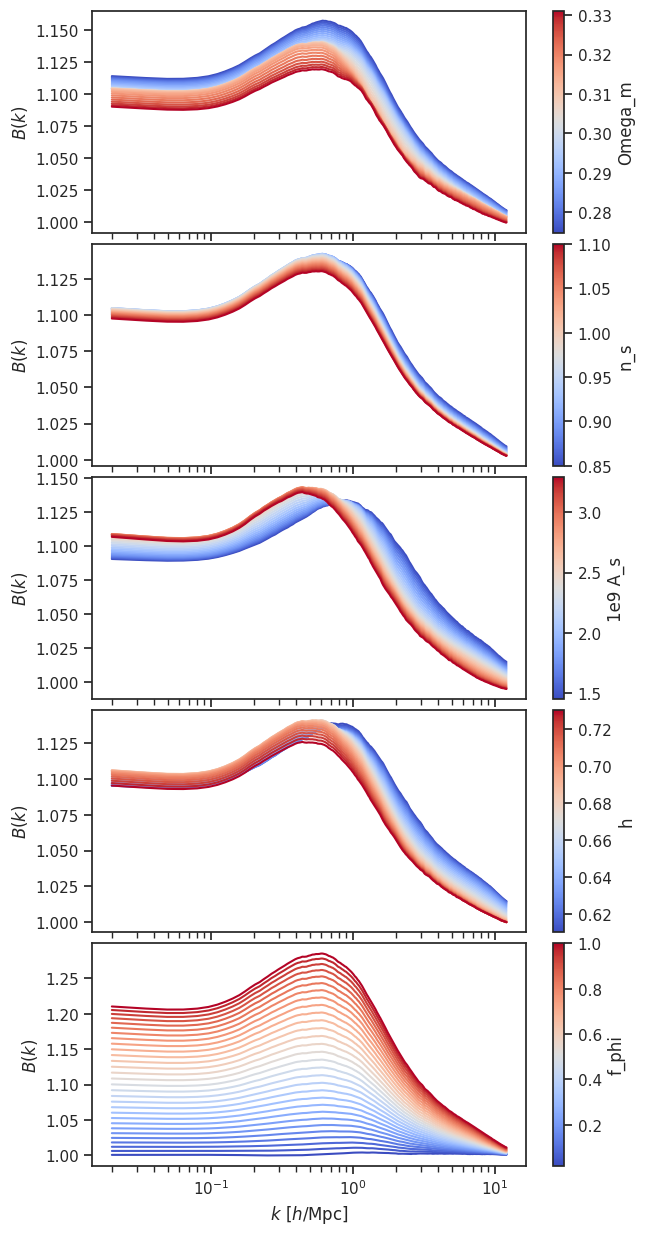

In [9]:
n_steps = 30
fig, axes = plt.subplots(len(PARAM_NAMES), 1, figsize=(7, 15), sharex=True)
plt.subplots_adjust(hspace=0.05)
for i, ax in enumerate(axes):
    values = np.linspace(PARAM_MIN[i], PARAM_MAX[i], n_steps)
    batch = np.tile(p_mid, (n_steps, 1))
    batch[:, i] = values
    k, Bk_mean, _ = emulate(batch, 0.0)
    norm = plt.Normalize(values.min(), values.max())
    for j in range(n_steps):
        ax.plot(k, Bk_mean[j], color=plt.cm.coolwarm(norm(values[j])), lw=1.5)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.coolwarm), ax=ax, label=PARAM_NAMES[i])
    ax.set_xscale('log')
    ax.set_ylabel(r'$B(k)$')
axes[-1].set_xlabel(r'$k\ [h/{\rm Mpc}]$');

## Emulator uncertainty across parameter space
Maximum emulator standard deviation over $k$, on a grid of $f_\phi$ and $10^9 A_s$ with the other parameters at the centre of the box ($z = 1$).

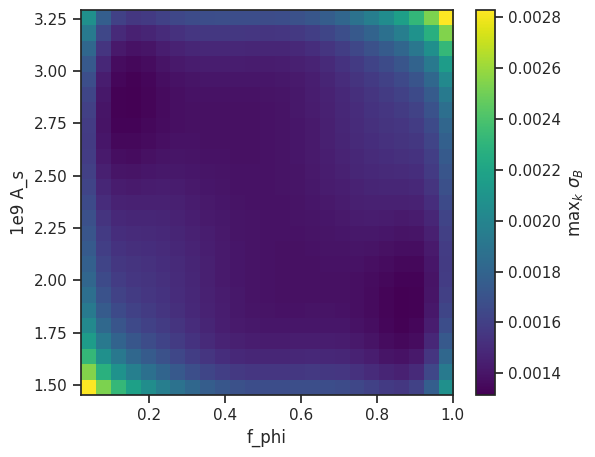

In [10]:
steps = 25
ix, iy = 4, 2
gx = np.linspace(PARAM_MIN[ix], PARAM_MAX[ix], steps)
gy = np.linspace(PARAM_MIN[iy], PARAM_MAX[iy], steps)
X, Y = np.meshgrid(gx, gy)
grid = np.tile(p_mid, (X.size, 1))
grid[:, ix], grid[:, iy] = X.ravel(), Y.ravel()

_, _, Bk_std = emulate(grid, 1.0)
max_std = Bk_std.max(axis=1).reshape(X.shape)

plt.figure(figsize=(6, 5))
plt.imshow(max_std, origin='lower', aspect='auto', cmap='viridis',
           extent=(gx[0], gx[-1], gy[0], gy[-1]))
plt.colorbar(label=r'max$_k\ \sigma_B$')
plt.xlabel(PARAM_NAMES[ix])
plt.ylabel(PARAM_NAMES[iy]);